# 05 – RQ3: human vs bot review activity

**RQ3:** How do the results change when review activity is separated into human and bot/agent review activity?

* **Reviewer type:** bot = GitHub account type `Bot` or a bot-like login (e.g. `openshift-ci-robot`); human = all other accounts. The account type alone misses bots on ordinary user accounts (Golzadeh et al., BotSE 2022).
* Not counted: the PR author and the agent's own working account on its PR. Human reviews addressed to an agent stay reviews; section 5 removes them as a robustness check.
* We repeat the RQ1 model (AI vs human) and the RQ2 model (per agent) with human-only and bot-only outcomes.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("ESS_DATA", ROOT / "data"))        # override only for testing
RESULTS = Path(os.environ.get("ESS_RESULTS", ROOT / "results"))
import pandas as pd
import analysis as an
import visualization as viz
viz.setup()
FIG, TAB = RESULTS / "figures", RESULTS / "tables"
TAB.mkdir(parents=True, exist_ok=True)
df = an.load(DATA / "processed/prs.parquet")
MIN_AGENT_PRS = 100   # an agent needs at least this many PRs for its own slope
AGENTS = an.agents_in(df, MIN_AGENT_PRS)
ORDER = ["Human"] + [an.AGENT_LABELS[a] for a in AGENTS]
print("agents analysed:", [an.AGENT_LABELS[a] for a in AGENTS])

agents analysed: ['Codex', 'Copilot', 'Claude Code', 'Cursor', 'Devin']


## 1. Who reviews the PRs?

Share of PRs reviewed by nobody / humans only / bots only / both – comparable to Duma et al. (EASE 2026), but within our sample.

col_0,No review,Human only,Bot only,Human and bot
author_group,,,,
Human,0.338,0.264,0.197,0.201
Codex,0.678,0.070,0.193,0.059
Copilot,0.461,0.284,0.074,0.181
Claude Code,0.515,0.156,0.228,0.101
Cursor,0.597,0.135,0.209,0.058
Devin,0.452,0.350,0.101,0.097


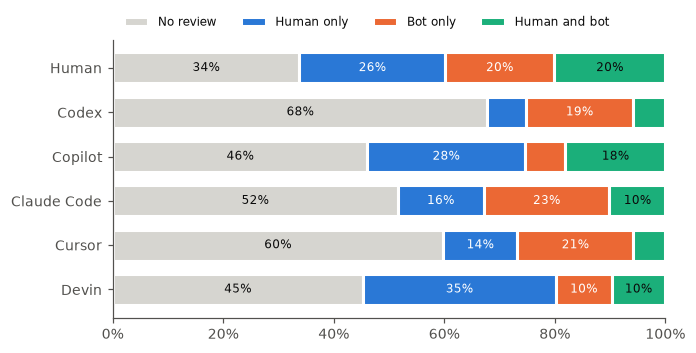

In [2]:
mix = an.reviewer_mix(df, "author_group").loc[ORDER]
mix.to_csv(TAB / "rq3_reviewer_mix.csv")
viz.reviewer_mix_bar(mix, FIG)
mix.round(3)

## 2. Steering of agents

Human discussion comments that address an agent (not part of review activity) and human reviews addressed to an agent (kept as reviews):

In [3]:
g = df.groupby("author_group")[["steering_comments_human", "comments_human", "steering_reviews_human", "reviews_human"]].sum().loc[ORDER]
g["steering_share_of_human_comments"] = g.steering_comments_human / (g.steering_comments_human + g.comments_human)
g["share_of_human_reviews_addressed_to_agent"] = g.steering_reviews_human / g.reviews_human
g.to_csv(TAB / "rq3_steering.csv")
g.round(3)

,steering_comments_human,comments_human,steering_reviews_human,reviews_human,steering_share_of_human_comments,share_of_human_reviews_addressed_to_agent
author_group,,,,,,
Human,1520,73949,23,154970,0.020,0.000
Codex,115,3092,2,4320,0.036,0.000
Copilot,24242,19120,2746,49342,0.559,0.056
Claude Code,1122,23675,19,39184,0.045,0.000
Cursor,74,1449,1,2522,0.049,0.000
Devin,58,1639,1,4705,0.034,0.000


## 3. RQ1 model split by reviewer type

In [4]:
rq3_rq1 = an.rq1_table(df, outcomes=an.OUTCOMES_BY_REVIEWER)
rq3_rq1.to_csv(TAB / "rq3_rq1_elasticities.csv", index=False)
rq3_rq1.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 44577 observations removed because of separation.
  warnings.warn(


...

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


,outcome,size,group,elasticity,se,ci_low,ci_high,p,n_used
0,Reviews (human reviewers),Changed lines (log),Human,0.138,0.005,0.129,0.147,0.000,284784
1,Reviews (human reviewers),Changed lines (log),AI agent,0.135,0.006,0.124,0.146,0.000,284784
2,Reviews (human reviewers),Changed lines (log),Difference (AI - Human),-0.004,0.006,-0.016,0.009,0.571,284784
3,Reviews (human reviewers),Changed files (log),Human,0.198,0.009,0.182,0.215,0.000,284784
4,Reviews (human reviewers),Changed files (log),AI agent,0.219,0.010,0.200,0.237,0.000,284784
5,Reviews (human reviewers),Changed files (log),Difference (AI - Human),0.020,0.011,-0.001,0.041,0.059,284784
6,Reviews (bot reviewers),Changed lines (log),Human,0.197,0.007,0.184,0.210,0.000,282533
7,Reviews (bot reviewers),Changed lines (log),AI agent,0.226,0.008,0.209,0.242,0.000,282533
8,Reviews (bot reviewers),Changed lines (log),Difference (AI - Human),0.028,0.008,0.012,0.044,0.001,282533
9,Reviews (bot reviewers),Changed files (log),Human,0.286,0.011,0.265,0.307,0.000,282533


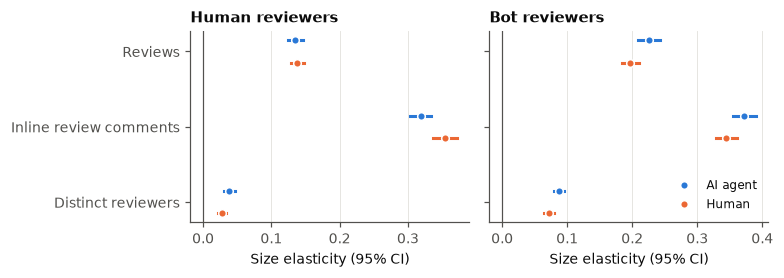

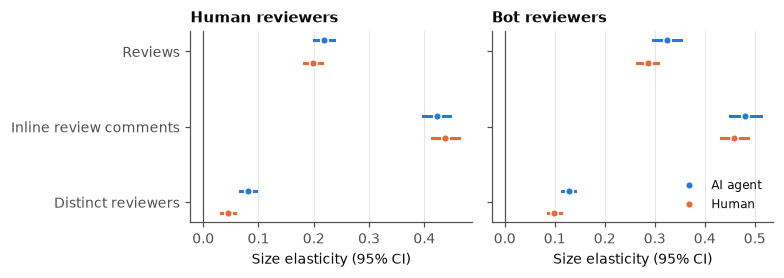

In [5]:
for size, label in an.SIZE_MEASURES.items():
    viz.reviewer_split_forest(rq3_rq1[rq3_rq1["size"] == label], FIG, f"fig_rq3_reviewer_split_{size.removeprefix('log_')}")

## 4. RQ2 model split by reviewer type

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21727 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 23978 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 44577 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 44577 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 27332 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 27332 observations removed because of separation.
  warnings.warn(


,outcome,size,chi2,df,p
0,Reviews (human reviewers),Changed lines (log),80.1704,4,0.0000
1,Reviews (human reviewers),Changed files (log),51.3273,4,0.0000
2,Reviews (bot reviewers),Changed lines (log),15.7939,4,0.0033
3,Reviews (bot reviewers),Changed files (log),7.8761,4,0.0962
4,Inline review comments (human reviewers),Changed lines (log),10.7960,4,0.0290
5,Inline review comments (human reviewers),Changed files (log),6.7495,4,0.1497
6,Inline review comments (bot reviewers),Changed lines (log),2.7306,4,0.6039
7,Inline review comments (bot reviewers),Changed files (log),8.5174,4,0.0744


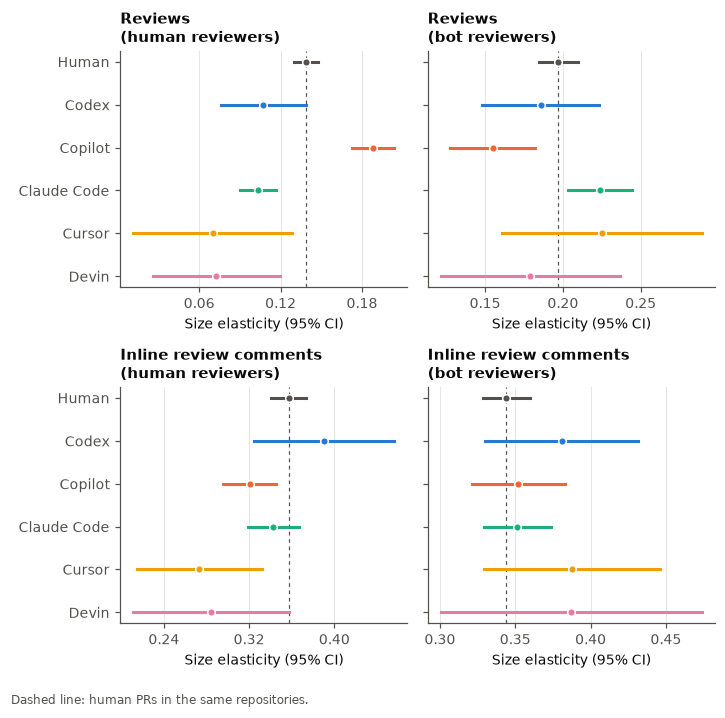

In [6]:
outcomes = {k: v for k, v in an.OUTCOMES_BY_REVIEWER.items() if not k.startswith("reviewers_")}
rq3_rq2, rq3_tests = an.rq2_table(df, AGENTS, outcomes=outcomes)
rq3_rq2.to_csv(TAB / "rq3_rq2_elasticities.csv", index=False)
rq3_tests.to_csv(TAB / "rq3_rq2_equal_slopes_test.csv", index=False)
viz.agent_forest(rq3_rq2[rq3_rq2["size"] == "Changed lines (log)"], FIG, "fig_rq3_agents_lines")
rq3_tests.round(4)

## 5. Robustness: without human reviews addressed to an agent

Human reviews whose text addresses an agent (`@copilot …`) mix code feedback with procedural instructions (manual check of 40 messages: 18 feedback, 22 procedural). Re-estimating the human-reviewer models without them shows whether they drive the result.

In [7]:
d = df.assign(reviews_human=df.reviews_human - df.steering_reviews_human,
              review_comments_human=df.review_comments_human - df.steering_review_comments_human)
human_only = {k: v for k, v in an.OUTCOMES_BY_REVIEWER.items() if k in ("reviews_human", "review_comments_human")}
rob = an.rq1_table(d, outcomes=human_only)
rob.to_csv(TAB / "rq3_robustness_without_agent_addressed_reviews.csv", index=False)
rob.round(3)

.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21806 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 21806 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 44662 observations removed because of separation.
  warnings.warn(


.venv/lib/python3.14/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
.venv/lib/python3.14/site-packages/pyfixest/estimation/models/fepois_.py:576: UserWarning: 44662 observations removed because of separation.
  warnings.warn(


,outcome,size,group,elasticity,se,ci_low,ci_high,p,n_used
0,Reviews (human reviewers),Changed lines (log),Human,0.138,0.005,0.129,0.148,0.000,284705
1,Reviews (human reviewers),Changed lines (log),AI agent,0.131,0.005,0.120,0.141,0.000,284705
2,Reviews (human reviewers),Changed lines (log),Difference (AI - Human),-0.008,0.006,-0.020,0.004,0.186,284705
3,Reviews (human reviewers),Changed files (log),Human,0.199,0.009,0.182,0.216,0.000,284705
4,Reviews (human reviewers),Changed files (log),AI agent,0.213,0.009,0.195,0.231,0.000,284705
5,Reviews (human reviewers),Changed files (log),Difference (AI - Human),0.014,0.010,-0.007,0.034,0.193,284705
6,Inline review comments (human reviewers),Changed lines (log),Human,0.355,0.009,0.339,0.372,0.000,261849
7,Inline review comments (human reviewers),Changed lines (log),AI agent,0.316,0.008,0.300,0.331,0.000,261849
8,Inline review comments (human reviewers),Changed lines (log),Difference (AI - Human),-0.040,0.011,-0.061,-0.019,0.000,261849
9,Inline review comments (human reviewers),Changed files (log),Human,0.439,0.013,0.415,0.464,0.000,261849


## 6. How to read the results

* Compare the *Human reviewers* and *Bot reviewers* panels with the pooled RQ1 result: if the AI-vs-human difference appears only for bot reviewers, the pooled effect is driven by automated review, not by people.
* Bot outcomes are zero in many repositories; those repositories drop out of bot models (see `n_used`).